### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 6
### Due: Wed. Nov 4, at 11.59pm CT
---

This problem has to do with density estimation and clustering. 

1. Read in `hw6_data_1.npy`. The dataset should consist of $1000$ samples with $2$ features. Note that the last column are the labels, not another feature. Make a $2$-D scatter plot of the data colored by their labels. 


2. Start with kernel density estimation on the data set. First, perform a grid search $5$-fold cross-validation to find the best bandwidth, testing $30$ bandwidths between $0.1$ and $1.0$. What is this best bandwidth? Using this best bandwidth, plot the two-dimensional kernel density estimate of the distribution. 


3. Now try a nearest neighbors approach to estimating the density. Use the Bayesian nearest neighbors option. Plot the estimated distribution. What value of $k$ neighbors do you need to make the plot look similar to your KDE distribution?


4. Now fit a Gaussian mixture model. Compute the AIC and BIC for the number of GMM components between $1$ and $10$. Plot these AIC and BIC values as a function of number of components. What is the optimal number according to the BIC? Fit the data set with this optimal number of GMM components, and create a new plot that shows the data set, the GMM component mean locations, and the $2$-sigma GMM component ellipses. *(Use the code below to help with plotting the ellipses.)*

In [19]:
# Kludge to fix the bug with draw_ellipse in astroML
from matplotlib.patches import Ellipse

def draw_ellipse(mu, C, scales=[1, 2, 3], ax=None, **kwargs):
    if ax is None:
        ax = plt.gca()

    # find principal components and rotation angle of ellipse
    sigma_x2 = C[0, 0]
    sigma_y2 = C[1, 1]
    sigma_xy = C[0, 1]

    alpha = 0.5 * np.arctan2(2 * sigma_xy,
                          (sigma_x2 - sigma_y2))
    tmp1 = 0.5 * (sigma_x2 + sigma_y2)
    tmp2 = np.sqrt(0.25 * (sigma_x2 - sigma_y2) ** 2 + sigma_xy ** 2)

    sigma1 = np.sqrt(tmp1 + tmp2)
    sigma2 = np.sqrt(tmp1 - tmp2)

    for scale in scales:
        ax.add_patch(Ellipse(xy=(mu[0], mu[1]),
                          width=2 * scale * sigma1, height=2 * scale * sigma2,
                          angle=alpha * 180. / np.pi,
                          **kwargs))

5. Now try Kmeans clustering with $5$ clusters. 
    - Use the `StandardScalar` to scale the data.
    - Fit the Kmeans model.
    - Find the cluster centers, and then inverse transform thse cluster centers back to the original unscaled coordinates.
    - Predict the labels for the scaled data.
    - Finally, make a two-panel side by side plot showing (a) the original data colored by its labels, then (b) the data colored by the Kmeans predicted labels, with cluster centers superposed.

### Solution

(1000, 2)


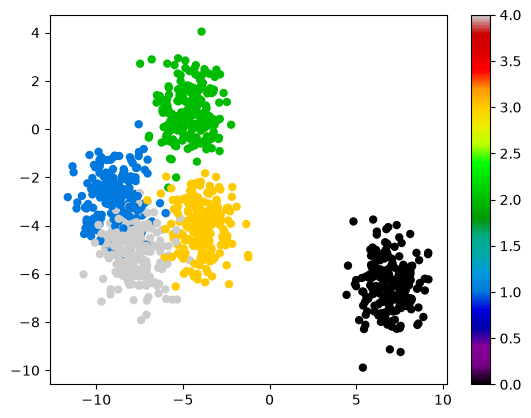

In [37]:
#1
import numpy as np
import matplotlib.pyplot as plt

# Load the data
data = np.load(r'.\hw_data\hw6_data_1.npy')

X = data[:, :2]
y = data[:, 2]

print(X.shape)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="nipy_spectral", edgecolor="None")
plt.colorbar()

Optimal bandwidth = 0.4724137931034482


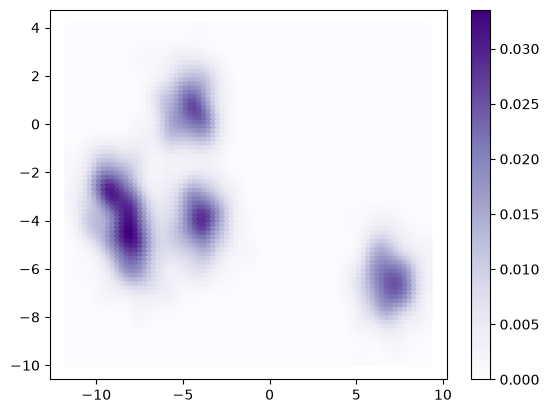

In [39]:
#2
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV

X = data[:, :2]

grid = GridSearchCV(KernelDensity(kernel='gaussian'),
                    {'bandwidth': np.linspace(0.1, 1.0, 30)},
                    cv=5)
grid.fit(X)

print("Optimal bandwidth =", grid.best_params_['bandwidth'])

kde = KernelDensity(kernel='gaussian',
                    bandwidth=grid.best_params_['bandwidth'])
kde.fit(X)

u = np.linspace(X[:,0].min(), X[:,0].max(), 80)
v = np.linspace(X[:,1].min(), X[:,1].max(), 80)

Xgrid = np.vstack(list(map(np.ravel, np.meshgrid(u, v)))).T
dens = np.exp(kde.score_samples(Xgrid))

plt.scatter(Xgrid[:,0], Xgrid[:,1], c=dens,
            cmap='Purples', edgecolor='None')
plt.colorbar()
plt.show()

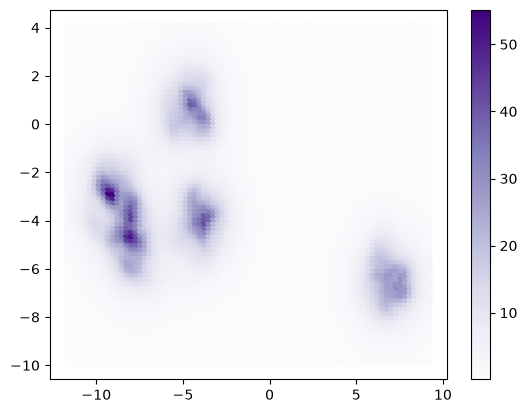

In [41]:
#3
from astroML.density_estimation import KNeighborsDensity

k = 30

knn = KNeighborsDensity(method='bayesian', n_neighbors=k)
knn.fit(X)

dens = knn.eval(Xgrid)

plt.scatter(Xgrid[:,0], Xgrid[:,1], c=dens,
            cmap='Purples', edgecolor='None')
plt.colorbar()
plt.show()

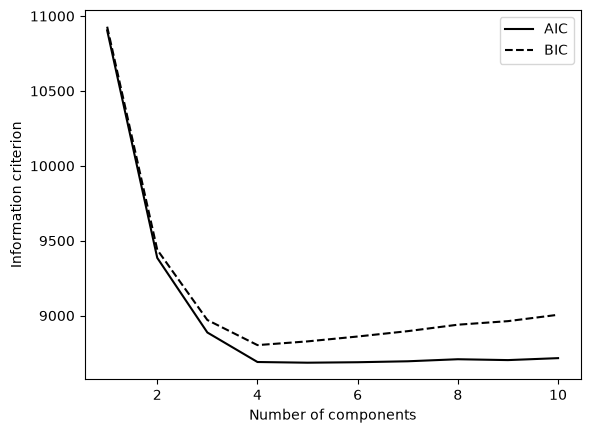

Optimal number of components = 4


In [45]:
#4.1
from sklearn.mixture import GaussianMixture

# Fit models with 1-10 components
N = np.arange(1, 11)
models = [None for i in range(len(N))]

for i in range(len(N)):
    models[i] = GaussianMixture(N[i]).fit(X)

# Compute AIC and BIC
AIC = [m.aic(X) for m in models]
BIC = [m.bic(X) for m in models]

# Plot AIC and BIC
plt.plot(N, AIC, '-k', label='AIC')
plt.plot(N, BIC, '--k', label='BIC')
plt.xlabel('Number of components')
plt.ylabel('Information criterion')
plt.legend()
plt.show()

# Best model according to BIC
M_best = models[np.argmin(BIC)]

print("Optimal number of components =", N[np.argmin(BIC)])

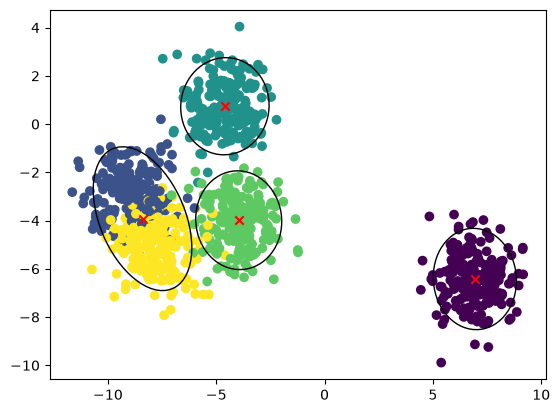

In [51]:
#4.2
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(4)
gmm.fit(X)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis')

for ii in range(4):
    draw_ellipse(gmm.means_[ii], gmm.covariances_[ii],
                 scales=[2], ax=plt.gca(),
                 fc='none', ec='k')

plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1],
            c='red', marker='x')

plt.show()

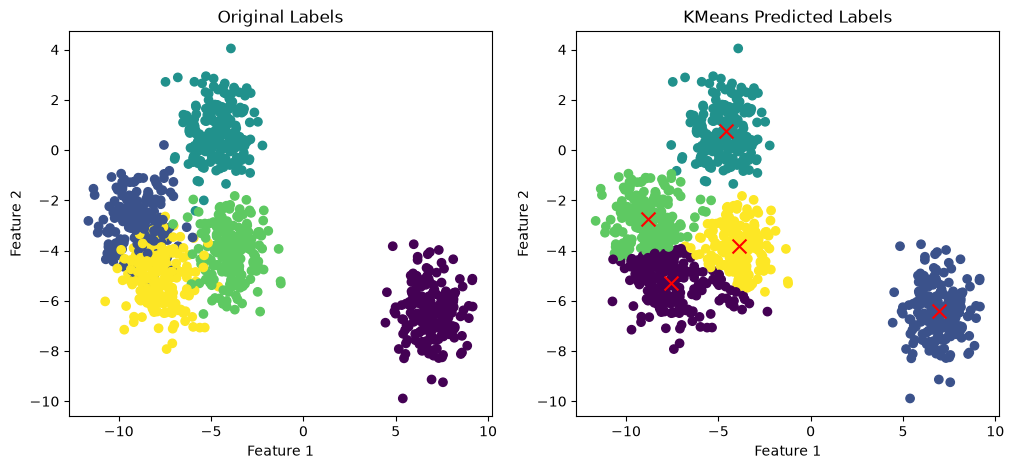

In [53]:
#5
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
Xscaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=5, random_state=0)
kmeans.fit(Xscaled)

labels = kmeans.predict(Xscaled)

centers = scaler.inverse_transform(kmeans.cluster_centers_)

fig = plt.figure(figsize=(12, 5))

# Original data
ax = fig.add_subplot(121)
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis')
ax.set_title('Original Labels')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')

# KMeans predictions
ax = fig.add_subplot(122)
ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
ax.scatter(centers[:, 0], centers[:, 1],
           c='red', marker='x', s=100)
ax.set_title('KMeans Predicted Labels')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')

plt.show()